# Material Hardness Prediction
## A reproducible regression study with a PCA comparison

**Research question:** How well can eleven numerical material descriptors predict the supplied hardness target, and does a compressed feature representation improve that prediction?

This notebook contains the complete implemented workflow: input checks, development/holdout splitting, four-model comparison, evaluation, permutation importance, error analysis, final predictions, and the supplementary PCA experiment described in the study guide.

**Run:** Open this notebook from the extracted project folder and select **Restart Kernel and Run All**. The three input CSV files are included in `data/`; no network access is needed to execute the analysis. Install `requirements.txt` first. For execution without a notebook interface, run `python scripts/run_notebook.py` from the project folder.

**Experimental record:** The original four-model comparison and holdout evaluation were completed first. PCA was investigated later on the same development folds only. The PCA section preserves that separation and does not replace the selected model or recompute a PCA holdout score.

**Implementation and sources:** This workflow was written for this project with AI assistance using standard pandas and scikit-learn APIs. The dataset is externally sourced, not newly collected by this project. Source links and a clear distinction between the implementation and the reference notebook are recorded at the end and in `DATA_SOURCES.txt`.

Mohs hardness represents scratch resistance on an ordinal scale. A value of 8 does not mean twice the physical hardness of 4. This synthetic benchmark follows a numerical regression formulation; transfer to independently collected materials remains untested.


## Experimental results

The following cells compute all results from the included data. The recorded reference run selected histogram gradient boosting and obtained holdout MedAE **0.5292**, versus **1.0000** for the median baseline (**47.1% lower error**). Holdout MAE was **0.8681**, with a 90th-percentile absolute error of **2.1760**.

The supplementary PCA boosting pipeline obtained development CV MedAE **0.5928**, compared with **0.5418** for boosting on the original features. These are separate development comparisons; no PCA holdout evaluation was performed. Interpretation cells below display the values calculated in this run.


## 1. Environment and reproducibility

Use Python 3.12 and the pinned packages in `requirements.txt`:

```bash
python -m venv .venv
source .venv/bin/activate  # Windows: .venv\Scripts\activate
python -m pip install -r requirements.txt
```

The requirements include notebook execution tools. Open the notebook in an existing Jupyter or VS Code installation, or use the included command-line runner. If a kernel needs registering, run `python -m ipykernel install --user --name material-hardness --display-name "Material hardness"` and select that kernel.


In [1]:
%matplotlib inline

from pathlib import Path
import json
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import median_absolute_error, mean_absolute_error
from sklearn.inspection import permutation_importance

SEED = 42
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

## 2. Load and check the data
The dataset contains 11 numeric predictors, including density, average atomic weight,
electron counts, electronegativity, and atomic radii. `Hardness` is the target; `id` is an
identifier and is excluded from the model.

Check schema, missing values, and exact duplicate predictor rows before modeling. This dataset
needs no missing-value imputation. Avoid adding preprocessing steps without a reason.

In [2]:
# Open this notebook from the extracted project folder.
DATA_DIR = Path('data')
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

def read_data(filename):
    path = DATA_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {path}. Keep the data/ folder next to project.ipynb."
        )
    return pd.read_csv(path)

train = read_data('train.csv')
test = read_data('test.csv')
sample = read_data('sample_submission.csv')
features = train.columns.drop(['id', 'Hardness']).tolist()
X, y = train[features], train['Hardness']

assert list(test.columns.drop('id')) == features
assert X.select_dtypes(include='number').shape[1] == len(features)
assert X.notna().all().all() and test[features].notna().all().all()
assert y.notna().all() and np.isfinite(X.to_numpy()).all()
assert np.isfinite(test[features].to_numpy()).all()
assert np.isfinite(y.to_numpy()).all()
assert X.shape[1] == 11
assert not X.duplicated().any(), 'Use grouped splitting if identical predictors exist.'
assert train['id'].is_unique and test['id'].is_unique

print(f'Training rows: {len(train):,}; test rows: {len(test):,}')
print(f'Predictors: {len(features)}; missing values: {X.isna().sum().sum()}')
print(f'Duplicate predictor rows: {X.duplicated().sum()}')
display(train.head(3))

Training rows: 10,407; test rows: 6,939
Predictors: 11; missing values: 0
Duplicate predictor rows: 0


,id,allelectrons_Total,density_Total,allelectrons_Average,val_e_Average,atomicweight_Average,ionenergy_Average,el_neg_chi_Average,R_vdw_element_Average,R_cov_element_Average,zaratio_Average,density_Average,Hardness
0,0,100.0,0.841611,10.0,4.8,20.612526,11.08810,2.766,1.732,0.860,0.496070,0.91457,6.0
1,1,100.0,7.558488,10.0,4.8,20.298893,12.04083,2.755,1.631,0.910,0.492719,0.71760,6.5
2,2,76.0,8.885992,15.6,5.6,33.739258,12.08630,2.828,1.788,0.864,0.481478,1.50633,2.5


## 3. Reserve a final evaluation set
Set aside 20% of the labeled data before exploratory analysis and model selection. Use only the
remaining 80% (the development set) for five-fold cross-validation. Every model sees the same folds.

A shuffled split is reasonable for this synthetic, tabular benchmark, which supplies no time or
material-family grouping. It is not a test of generalization to unseen mineral families. Real-world
deployment would need grouping by material/source or another split reflecting intended use.

Development: 8,325 rows; untouched holdout: 2,082 rows


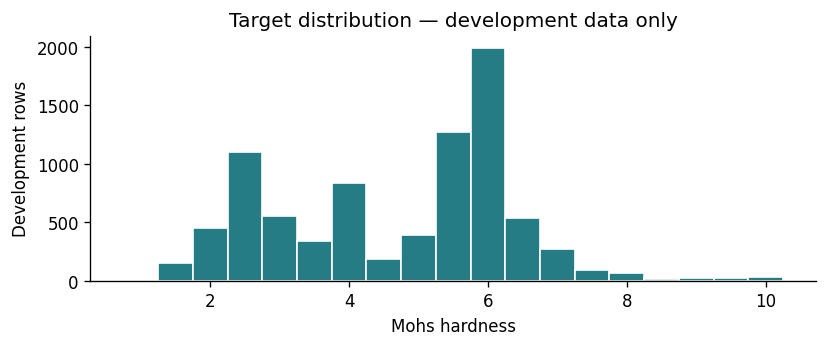

,min,50%,max
allelectrons_Total,0.0,100.000,15300.000
density_Total,0.0,10.671,643.094
allelectrons_Average,0.0,12.600,67.000
val_e_Average,0.0,4.714,6.000
atomicweight_Average,0.0,26.204,167.400
ionenergy_Average,0.0,11.203,15.246
el_neg_chi_Average,0.0,2.706,3.443
R_vdw_element_Average,0.0,1.734,2.250
R_cov_element_Average,0.0,0.918,1.616
zaratio_Average,0.0,0.488,0.826


In [3]:
X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
assert set(X_dev.index).isdisjoint(X_holdout.index)
print(f'Development: {len(X_dev):,} rows; untouched holdout: {len(X_holdout):,} rows')

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(y_dev, bins=np.arange(0.75, 10.51, 0.5), color='#267C85', edgecolor='white')
ax.set(xlabel='Mohs hardness', ylabel='Development rows',
       title='Target distribution — development data only')
plt.tight_layout()
plt.show()
display(X_dev.describe().T[['min', '50%', 'max']].round(3))

## 4. Define success and compare models
The primary selection metric is **median absolute error (MedAE)**:

\[\operatorname{MedAE}=\operatorname{median}(|y_i-\hat y_i|)\]

Lower is better. A MedAE of 0.5 means at least half of the absolute errors are at most roughly
0.5 hardness units. It is not an accuracy percentage. Because MedAE can hide severe mistakes in
the remaining cases, also report **mean absolute error (MAE)** and the **90th-percentile error**.

| Model | Why include it? |
|---|---|
| Median baseline | Predict the development-fold median for every row; a useful minimum benchmark. |
| Ridge regression | Check whether a regularized linear relationship is sufficient. |
| Random Forest | Learn nonlinear thresholds and interactions by averaging decision trees. |
| Histogram gradient boosting | Build small trees sequentially, each reducing remaining loss. |

Scale features inside the Ridge pipeline, so scaling is learned separately in every training fold.
Tree models do not need scaling. All model settings are fixed before looking at holdout results.
There is no hyperparameter search. The forest uses 200 trees and at least three samples per leaf.
Boosting uses 250 iterations, a small learning rate, at most 15 leaves per tree, and L2 regularization.

Boosting's `absolute_error` training loss targets the conditional median by minimizing **mean**
absolute error. It does **not** directly optimize the median-of-errors selection metric.
Select the model using observed cross-validation MedAE.

In [4]:
models = {
    'Median baseline': DummyRegressor(strategy='median'),
    'Ridge regression': make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    'Random Forest': RandomForestRegressor(
        n_estimators=200, min_samples_leaf=3, random_state=SEED, n_jobs=2
    ),
    'Gradient boosting': HistGradientBoostingRegressor(
        loss='absolute_error', learning_rate=0.06, max_iter=250,
        max_leaf_nodes=15, min_samples_leaf=20, l2_regularization=1.0,
        early_stopping=False, random_state=SEED
    ),
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
records = []
for name, model in models.items():
    scores = cross_validate(
        model, X_dev, y_dev, cv=cv, n_jobs=1, error_score='raise',
        scoring={'medae': 'neg_median_absolute_error', 'mae': 'neg_mean_absolute_error'}
    )
    fold_medae = -scores['test_medae']
    records.append({
        'Model': name, 'CV MedAE': fold_medae.mean(),
        'Fold SD': fold_medae.std(ddof=1), 'CV MAE': -scores['test_mae'].mean(),
    })
    print(f'{name}: CV MedAE = {fold_medae.mean():.4f}')

cv_results = pd.DataFrame(records).set_index('Model').sort_values('CV MedAE')
display(cv_results.round(4))
best_name = cv_results.index[0]
print('Selected using development CV only:', best_name)

Median baseline: CV MedAE = 1.0400
Ridge regression: CV MedAE = 0.9601


Random Forest: CV MedAE = 0.6383


Gradient boosting: CV MedAE = 0.5418


,CV MedAE,Fold SD,CV MAE
Model,,,
Gradient boosting,0.5418,0.0182,0.8812
Random Forest,0.6383,0.0248,0.8992
Ridge regression,0.9601,0.0491,1.1777
Median baseline,1.0400,0.0894,1.4432


Selected using development CV only: Gradient boosting


**Interpretation of this run:** The average CV MedAE was 1.0400 for the constant baseline, 0.9601 for Ridge, 0.6383 for Random Forest, and 0.5418 for gradient boosting. The tree models improve on the linear baseline, supporting the usefulness of nonlinear relationships for this benchmark. The lower score selects boosting under the stated rule; it does not prove that it is universally the best algorithm.

## 5. Evaluate the selected model once
Refit the selected estimator on all development rows. Compare it with the median baseline on
the previously untouched holdout. This estimates performance after model selection. Do not
change settings in response to this result and still describe the holdout as untouched.
Fold standard deviation above describes variation between folds, not a confidence interval.

In [5]:
selected = clone(models[best_name]).fit(X_dev, y_dev)
baseline = clone(models['Median baseline']).fit(X_dev, y_dev)
pred = selected.predict(X_holdout)
baseline_pred = baseline.predict(X_holdout)

def report(actual, predicted):
    errors = np.abs(np.asarray(actual) - predicted)
    return {'MedAE': median_absolute_error(actual, predicted),
            'MAE': mean_absolute_error(actual, predicted),
            '90th percentile error': np.quantile(errors, 0.90)}

holdout_results = pd.DataFrame({
    'Median baseline': report(y_holdout, baseline_pred),
    best_name: report(y_holdout, pred),
}).T
display(holdout_results.round(4))
improvement = 1 - holdout_results.loc[best_name, 'MedAE'] / holdout_results.loc['Median baseline', 'MedAE']
print(f'Holdout MedAE reduction versus baseline: {improvement:.1%}')
print('These are local holdout results from the development-trained model.')

,MedAE,MAE,90th percentile error
Median baseline,1.0000,1.4227,3.200
Gradient boosting,0.5292,0.8681,2.176


Holdout MedAE reduction versus baseline: 47.1%
These are local holdout results from the development-trained model.


## 6. Explain what the model uses
Permutation importance shuffles one predictor while keeping the trained model fixed. If the
error rises, the model relied on that predictor. Here, importance is the increase in **MAE**,
which captures changes across all observations and complements the primary selection metric.

Use holdout data for this diagnostic after final scoring. No feature selection or model changes
follow this inspection. Importance indicates predictive reliance, not a causal effect. Correlated
features may substitute for each other, understating their individual importance; shuffling can
also create unrealistic combinations. The error bars reflect five shuffles, not full uncertainty.

,Feature,MAE increase,Shuffle SD
2,allelectrons_Average,0.1157,0.0114
5,ionenergy_Average,0.0957,0.0045
3,val_e_Average,0.0757,0.0047
4,atomicweight_Average,0.0715,0.0057
8,R_cov_element_Average,0.0694,0.0048
9,zaratio_Average,0.0633,0.0042
6,el_neg_chi_Average,0.0251,0.0023
10,density_Average,0.0219,0.0021
1,density_Total,0.0160,0.0010
7,R_vdw_element_Average,0.0150,0.0023


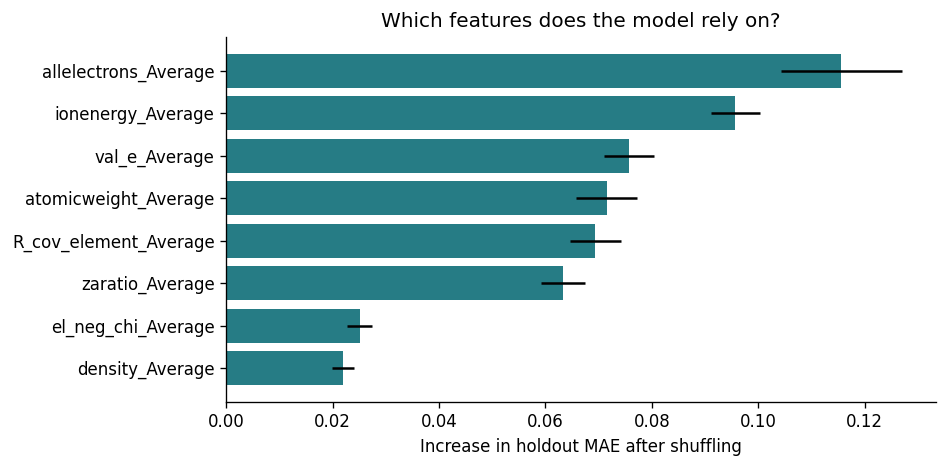

In [6]:
permutation = permutation_importance(
    selected, X_holdout, y_holdout, scoring='neg_mean_absolute_error',
    n_repeats=5, random_state=SEED, n_jobs=1
)
importance = pd.DataFrame({
    'Feature': features, 'MAE increase': permutation.importances_mean,
    'Shuffle SD': permutation.importances_std,
}).sort_values('MAE increase', ascending=False)
display(importance.round(4))

top = importance.head(8).sort_values('MAE increase')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top['Feature'], top['MAE increase'], xerr=top['Shuffle SD'], color='#267C85')
ax.set(xlabel='Increase in holdout MAE after shuffling', title='Which features does the model rely on?')
plt.tight_layout()
plt.show()

**Interpretation of this run:** Shuffling average electron count increased MAE by about 0.116; shuffling average ionization energy increased it by about 0.096. These were the two largest measured importances. Describe them as features this fitted model relied on, rather than asserting that they physically cause hardness.

## 7. Look at the failures
An overall metric can hide weak performance at the extremes. Inspect errors by actual hardness
and examine large misses. These bands are diagnostic groups, not a new classification target.
The true hardness is unavailable at prediction time, so do not use these groups to choose a model
for an unlabeled test row.

,Rows,MedAE,MAE
Hardness band,,,
1–3,564,0.9004,1.2192
>3–6,1266,0.3823,0.6289
>6–10,252,0.9758,1.2837


,Actual,Predicted,Absolute error,Hardness band
8767,7.8,2.642,5.158,>6–10
1349,9.5,4.707,4.793,>6–10
8101,1.5,5.916,4.416,1–3
6862,1.8,6.010,4.210,1–3
5573,10.0,5.811,4.189,>6–10


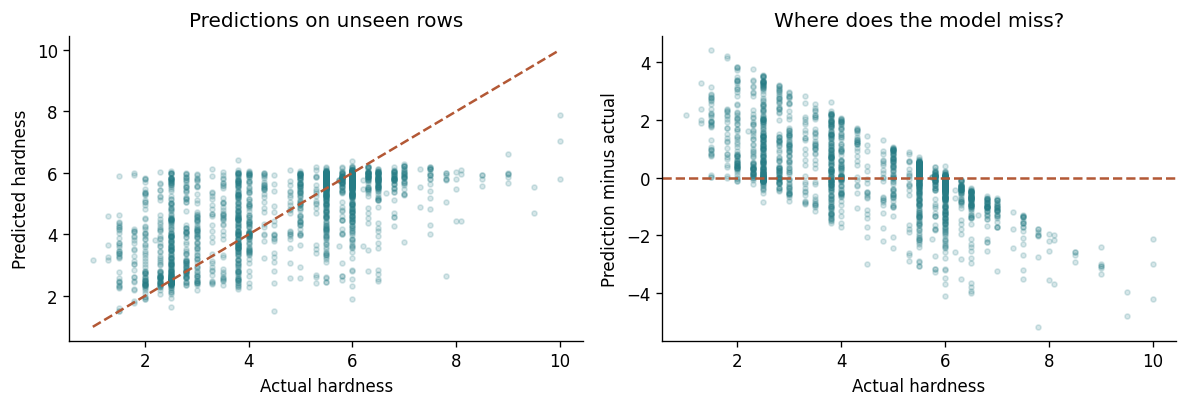

In [7]:
errors = pd.DataFrame({
    'Actual': y_holdout, 'Predicted': pred,
    'Absolute error': np.abs(y_holdout - pred),
})
errors['Hardness band'] = pd.cut(
    errors['Actual'], bins=[0, 3, 6, 10], labels=['1–3', '>3–6', '>6–10']
)
band_results = errors.groupby('Hardness band', observed=True).agg(
    Rows=('Absolute error', 'size'),
    MedAE=('Absolute error', 'median'), MAE=('Absolute error', 'mean'),
)
display(band_results.round(4))
display(errors.nlargest(5, 'Absolute error').round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(errors['Actual'], errors['Predicted'], s=9, alpha=0.18, color='#267C85')
axes[0].plot([1, 10], [1, 10], '--', color='#B35835')
axes[0].set(xlabel='Actual hardness', ylabel='Predicted hardness', title='Predictions on unseen rows')
axes[1].scatter(errors['Actual'], errors['Predicted'] - errors['Actual'], s=9, alpha=0.18, color='#267C85')
axes[1].axhline(0, linestyle='--', color='#B35835')
axes[1].set(xlabel='Actual hardness', ylabel='Prediction minus actual', title='Where does the model miss?')
plt.tight_layout()
plt.show()

**Interpretation of this run:** Median error was 0.382 for actual hardness above 3 through 6, compared with 0.900 for 1–3 and 0.976 for above 6 through 10. The residual plot shows many soft materials being overestimated and hard materials being underestimated. Predictions concentrate toward the middle of the scale. Limited information in the features and uneven data coverage are possible explanations, not established causes. The high-hardness band has only 252 holdout examples. This is a useful limitation to discuss in an interview, even though the overall score improves substantially.

## 8. Fit the final model and export predictions

After evaluation, refit the selected configuration on all labelled rows and predict the unlabelled test rows. The test targets are unavailable, so the output has no separately measured test score. The earlier holdout result belongs to the development-trained model.

Check the row count, exact output columns, identifier alignment, and finite values before writing `results/submission.csv`. The filename follows the supplied output template. Also save the comparison, evaluation, and diagnostic tables for review.


In [8]:
final_model = clone(models[best_name]).fit(X, y)
submission = pd.DataFrame({'id': test['id'], 'Hardness': final_model.predict(test[features])})
assert list(submission.columns) == list(sample.columns)
assert submission['id'].equals(sample['id'])
assert len(submission) == len(test) and np.isfinite(submission['Hardness']).all()

ARTIFACTS = RESULTS
ARTIFACTS.mkdir(exist_ok=True)
submission.to_csv(ARTIFACTS / 'submission.csv', index=False)
cv_results.to_csv(ARTIFACTS / 'cross_validation.csv')
holdout_results.to_csv(ARTIFACTS / 'holdout_metrics.csv')
importance.to_csv(ARTIFACTS / 'feature_importance.csv', index=False)
band_results.to_csv(ARTIFACTS / 'error_by_hardness.csv')
print(f'Saved {len(submission):,} predictions to {ARTIFACTS / "submission.csv"}')
display(submission.head())

Saved 6,939 predictions to results/submission.csv


,id,Hardness
0,10407,2.622323
1,10408,2.500134
2,10409,5.848365
3,10410,4.280956
4,10411,4.900272


## 9. Supplementary experiment: does PCA help?

PCA constructs linear combinations of the inputs that preserve input variance. It does not use hardness labels to select its directions, so preserving variance does not guarantee preserving predictive information.

This experiment is deliberately separate from the original selection and holdout evaluation. Test two fixed pipelines on **development data only**: `StandardScaler → PCA (95% variance) → Ridge`, and the same preprocessing followed by the original boosting configuration. Each fold learns its own scaling and projection. Keep the original final model and exported predictions unchanged.

The comparison holds the row splits, scoring rule, and estimator configurations fixed. Returned fold estimators reveal the number of retained components. No PCA variant is scored on the holdout.


In [9]:
pca_rows = []
pca_fold_details = {}
for label, estimator in {
    'PCA 95% + Ridge': Ridge(alpha=10.0),
    'PCA 95% + Gradient boosting': clone(models['Gradient boosting']),
}.items():
    candidate = make_pipeline(
        StandardScaler(), PCA(n_components=0.95, svd_solver='full'), estimator
    )
    scores = cross_validate(
        candidate, X_dev, y_dev, cv=cv, n_jobs=1, error_score='raise',
        scoring={'medae': 'neg_median_absolute_error',
                 'mae': 'neg_mean_absolute_error'},
        return_estimator=True,
    )
    fold_errors = -scores['test_medae']
    dimensions = [int(fit.named_steps['pca'].n_components_)
                  for fit in scores['estimator']]
    pca_rows.append({
        'Model': label, 'CV MedAE': fold_errors.mean(),
        'Fold SD': fold_errors.std(ddof=1),
        'CV MAE': -scores['test_mae'].mean(),
        'Components per fold': ','.join(map(str, dimensions)),
    })
    pca_fold_details[label] = {
        'medae': fold_errors.tolist(), 'components': dimensions
    }

pca_results = pd.DataFrame(pca_rows).set_index('Model')
comparison = pd.concat([
    cv_results.loc[['Ridge regression', 'Gradient boosting'],
                   ['CV MedAE', 'Fold SD', 'CV MAE']],
    pca_results[['CV MedAE', 'Fold SD', 'CV MAE']],
])
display(comparison.round(4))
display(pca_results[['Components per fold']])
pca_results.to_csv(RESULTS / 'pca_comparison.csv')


,CV MedAE,Fold SD,CV MAE
Model,,,
Ridge regression,0.9601,0.0491,1.1777
Gradient boosting,0.5418,0.0182,0.8812
PCA 95% + Ridge,0.9755,0.0466,1.1845
PCA 95% + Gradient boosting,0.5928,0.0396,0.9505


,Components per fold
Model,
PCA 95% + Ridge,"8,8,8,7,8"
PCA 95% + Gradient boosting,"8,8,8,7,8"


### Inspect the variance spectrum

For explanation, fit a separate scaler and PCA on all development inputs and plot cumulative explained variance. This descriptive fit is not used to transform or score any validation fold. Its component counts can differ from an individual fold because it sees different training rows.


,Components,Cumulative variance
0,1,0.3972
1,2,0.6192
2,3,0.7611
3,4,0.8381
4,5,0.8934
5,6,0.9237
6,7,0.9480
7,8,0.9700
8,9,0.9868
9,10,0.9992


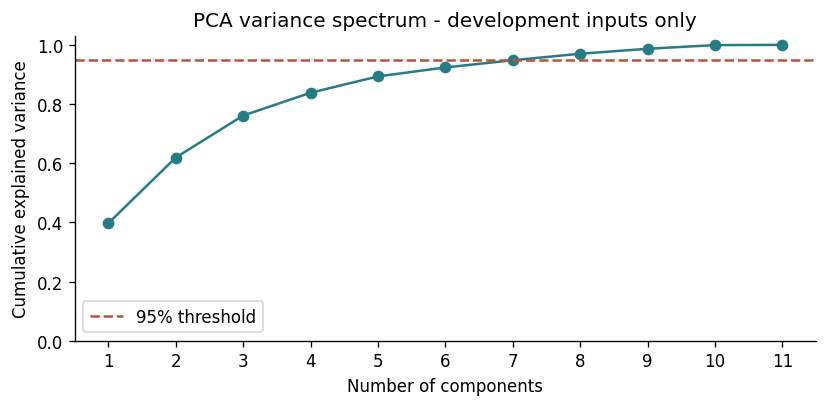

1640

In [10]:
descriptive_pca = make_pipeline(
    StandardScaler(), PCA(svd_solver='full')
).fit(X_dev)
variance_ratios = descriptive_pca.named_steps['pca'].explained_variance_ratio_
cumulative_variance = variance_ratios.cumsum()
variance_table = pd.DataFrame({
    'Components': np.arange(1, len(features) + 1),
    'Cumulative variance': cumulative_variance,
})
display(variance_table.round(4))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(variance_table['Components'], cumulative_variance,
        marker='o', color='#267C85')
ax.axhline(0.95, linestyle='--', color='#B35835', label='95% threshold')
ax.set(xlabel='Number of components', ylabel='Cumulative explained variance',
       title='PCA variance spectrum - development inputs only',
       xticks=range(1, len(features) + 1), ylim=(0, 1.03))
ax.legend()
plt.tight_layout()
plt.show()

pca_diagnostics = {
    'sklearn_version': sklearn.__version__,
    'development_rows': len(X_dev), 'features': features,
    'holdout_evaluated': False, 'folds': pca_fold_details,
    'development_variance_ratios': variance_ratios.tolist(),
    'development_cumulative_variance': cumulative_variance.tolist(),
    'components_for_95_percent': int(
        np.searchsorted(cumulative_variance, 0.95, side='right') + 1
    ),
}
(RESULTS / 'pca_diagnostics.json').write_text(
    json.dumps(pca_diagnostics, indent=2)
)


In [11]:
original_cv = cv_results.loc['Gradient boosting', 'CV MedAE']
compressed_cv = pca_results.loc['PCA 95% + Gradient boosting', 'CV MedAE']
relative_change = (compressed_cv / original_cv - 1) * 100
print(f"Original-feature boosting CV MedAE: {original_cv:.4f}")
print(f"PCA boosting CV MedAE: {compressed_cv:.4f}")
print(f"Relative change in error: {relative_change:+.1f}% (positive is worse)")
print(f"Variance with 5 components: {cumulative_variance[4]:.2%}")
print(f"Variance with 8 components: {cumulative_variance[7]:.2%}")
print('The original selected configuration and submission have not been changed.')


Original-feature boosting CV MedAE: 0.5418
PCA boosting CV MedAE: 0.5928
Relative change in error: +9.4% (positive is worse)
Variance with 5 components: 89.34%
Variance with 8 components: 97.00%
The original selected configuration and submission have not been changed.


### Interpretation and experiment count

In the reference run, PCA increased boosting's mean CV MedAE from approximately 0.542 to 0.593 (about 9.4% worse); Ridge also became slightly worse. Five components retained approximately 89.34% of standardized development variance and eight retained approximately 97.00%. Retained fold dimensions were 8, 8, 8, 7, and 8.

Possible reasons include loss of target-relevant directions and a rotation that changes how easily axis-aligned trees express useful regions. These are plausible mechanisms, not causes demonstrated by this comparison. The result applies to the two tested variants; it does not establish that all PCA configurations are ineffective.

The original workflow has four model families and 23 supervised fits: 20 fold fits, two development fits for holdout evaluation, and one full-data fit. The supplementary variants add ten supervised fits, for **33 supervised fits in total**, plus the learned preprocessing stages and the separate descriptive PCA fit.


## 10. Explain this project in an interview
Use the generated summary below after reproducing and understanding the notebook.

In [12]:
print(
    f'I built a regression model to estimate mineral hardness from 11 numeric material properties. '
    f'I reserved 20% of the labeled rows for final evaluation and compared a median baseline, '
    f'Ridge, Random Forest, and gradient boosting using five-fold cross-validation on the remainder. '
    f'{best_name} had the lowest average cross-validation median absolute error. '
    f'On the holdout, its MedAE was {holdout_results.loc[best_name, "MedAE"]:.3f}, '
    f'compared with {holdout_results.loc["Median baseline", "MedAE"]:.3f} for the baseline. '
    f'I also reported mean and tail errors, checked which features the model relied on, '
    f'and examined errors across hardness ranges. A separate PCA comparison used only development folds; '
    f'its boosting CV MedAE was {compressed_cv:.3f}, versus {original_cv:.3f} with original inputs. '
    f'The dataset is synthetic, so testing on '
    f'real, independently collected materials would be the next validation step.'
)

I built a regression model to estimate mineral hardness from 11 numeric material properties. I reserved 20% of the labeled rows for final evaluation and compared a median baseline, Ridge, Random Forest, and gradient boosting using five-fold cross-validation on the remainder. Gradient boosting had the lowest average cross-validation median absolute error. On the holdout, its MedAE was 0.529, compared with 1.000 for the baseline. I also reported mean and tail errors, checked which features the model relied on, and examined errors across hardness ranges. A separate PCA comparison used only development folds; its boosting CV MedAE was 0.593, versus 0.542 with original inputs. The dataset is synthetic, so testing on real, independently collected materials would be the next validation step.


### Questions you should be able to answer

**Why regression?** The competition asks for a numeric hardness estimate. Although the Mohs scale
is ordinal, regression follows its stated task and evaluation. An ordinal model is a reasonable
future comparison, not a claim that the physical scale has equal intervals.

**Why keep a constant and a linear baseline?** They show whether feature-based modeling helps
and whether nonlinear models add value. The median baseline is a conventional robust starting
point; it is not guaranteed to be the best constant for the MedAE metric.

**How does Random Forest differ from boosting?** A forest averages trees trained with randomness
to reduce variance. Boosting adds trees sequentially to reduce the current model's loss. Both
can learn nonlinear interactions without explicitly creating polynomial features.

**How did you prevent leakage?** The holdout is reserved before exploratory analysis and selection.
The target and ID are excluded. Ridge scaling is fitted inside each CV training fold. No test labels
or original-dataset targets are used. No exact duplicated predictor rows were found. The schema
does not expose material-family identities, so family-level leakage cannot be ruled out by this check.

**Why two error metrics?** MedAE follows the competition and summarizes the typical absolute error.
MAE and the 90th-percentile error expose large misses that the median can conceal.

**Why is PCA absent from the final model?** There are only eleven named predictors. The supplementary development-only comparison tested 95%-variance PCA with Ridge and boosting, and both variants worsened mean CV MedAE. This supports retaining the original representation for this configuration; no exhaustive PCA search was performed.

**Is feature importance an explanation of physics?** No. It describes this model's reliance on its
inputs. Correlation, synthetic data generation, and unrealistic shuffled combinations limit
interpretation. It does not establish how intervening on a property changes hardness.

**What would you improve next?** First collect independent real data and useful material-family
labels. Then test grouped validation, quantify uncertainty, and investigate the worst error groups.
If tuning follows holdout inspection, use a new untouched evaluation set for the next final result.

**What can you claim?** A reproducible local regression benchmark with validation and error analysis.
No leaderboard rank, clinical/industrial readiness, causal discovery, or real-world accuracy has
been established by this notebook.

### References
- [Kaggle competition](https://www.kaggle.com/competitions/playground-series-s3e25)
- [Data mirror at the pinned commit](https://github.com/Abhinandan57/Kaggle_Competition_MohsHardness/tree/6381c7f2738834d5b99efb004926ae2b7e437162)
- [Histogram gradient boosting documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html)
- [Permutation importance and its limitations](https://scikit-learn.org/stable/modules/permutation_importance.html)

### Implementation provenance
The workflow and explanatory text were developed in this project with AI assistance, rather than copied from the linked reference notebook. That reference uses a different Random Forest/PCA search workflow. Standard library imports and estimator calls are conventional; similarity in those lines is expected and is not a novelty claim. The data source is credited because independent implementation does not make externally supplied data original to this project.
